# CIFAR-10: сравнение KNN, SVM, MLP и CNN

Исследуем распознавание десяти классов цветных изображений.
KNN и SVM работают с векторами исходных пикселей; MLP обучает
нелинейные преобразования этих векторов, а CNN использует пространственную
структуру изображения через свёртки.

**Цели:** сопоставить подходы, отделить train, validation и test,
и корректно интерпретировать результаты при разных объёмах обучения.

**Ограничение:** KNN/SVM обучаются на 5 000 изображениях, а MLP/CNN —
на оставшемся после выделения validation полном обучающем пуле.
Это сравнение конкретных экспериментов с разными бюджетами данных,
а не доказательство превосходства архитектуры при одинаковых условиях.

Нужны NumPy, Matplotlib, scikit-learn и TensorFlow. Выполняйте ячейки
сверху вниз; первый запуск может скачивать CIFAR-10. Обучение требует времени.

## 1. Подготовка данных и воспроизводимость

Исходные данные: 50 000 train и 10 000 test изображений размером 32 × 32 × 3.
Из train выделяем 5 000 объектов для validation со стратификацией по классам.
Остаётся 45 000 изображений для обучения нейросетей. Из того же пула выбираем
стратифицированную подвыборку из 5 000 объектов для KNN/SVM.

Нормализация одинакова для всех моделей: `float32`, пиксели в `[0, 1]`.
Test не передаётся в `fit` и используется только для итоговой оценки.
Нейросети обучаются 10 эпох с batch size 64.

Фиксируем seed для разбиений и обучения, включаем детерминированные
операции TensorFlow. Повторяемость ожидается в одном и том же окружении;
между версиями библиотек и устройствами результат может отличаться.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

seed = 42
classical_train_size = 5000
validation_size = 5000
epochs = 10
batch_size = 64

tf.keras.utils.set_random_seed(seed)
tf.config.experimental.enable_op_determinism()
rng = np.random.default_rng(seed)

(x_train, y_train), (x_test, y_test) = cifar10.load_data()
y_train = y_train.ravel()
y_test = y_test.ravel()

x_fit, x_val, y_fit, y_val = train_test_split(
    x_train, y_train, test_size=validation_size,
    stratify=y_train, random_state=seed,
)
del x_train, y_train

x_classical, _, y_classical, _ = train_test_split(
    x_fit, y_fit, train_size=classical_train_size,
    stratify=y_fit, random_state=seed,
)
x_fit = x_fit.astype("float32")
x_fit /= 255.0
x_val = x_val.astype("float32")
x_val /= 255.0
x_classical = x_classical.astype("float32")
x_classical /= 255.0
x_test = x_test.astype("float32")
x_test /= 255.0

X_classical = x_classical.reshape(len(x_classical), -1)
X_fit = x_fit.reshape(len(x_fit), -1)
X_val = x_val.reshape(len(x_val), -1)
X_test = x_test.reshape(len(x_test), -1)

y_fit_categorical = to_categorical(y_fit, num_classes=10)
y_val_categorical = to_categorical(y_val, num_classes=10)
y_test_categorical = to_categorical(y_test, num_classes=10)

print("Train KNN/SVM:", X_classical.shape)
print("Train MLP/CNN:", x_fit.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)

Train KNN/SVM: (5000, 3072)
Train MLP/CNN: (45000, 32, 32, 3)
Validation: (5000, 32, 32, 3)
Test: (10000, 32, 32, 3)


## 2. Классические модели на 5 000 изображениях

Используем KNN с пятью соседями и линейный SVM с `C=1.0`.
Вектор каждого изображения содержит 3 072 признака.
Расстояние между такими векторами не учитывает пространственную структуру
так, как это делает свёртка. Низкая accuracy не означает, что сами методы
непригодны для других представлений данных или задач.

In [2]:
knn_model = KNeighborsClassifier(n_neighbors=5)
svm_model = SVC(kernel="linear", C=1.0, random_state=seed)

knn_model.fit(X_classical, y_classical)
svm_model.fit(X_classical, y_classical)

y_pred_knn = knn_model.predict(X_test)
y_pred_svm = svm_model.predict(X_test)
knn_accuracy = accuracy_score(y_test, y_pred_knn)
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print(f"Test accuracy KNN: {knn_accuracy:.4f}")
print(f"Test accuracy SVM: {svm_accuracy:.4f}")

Test accuracy KNN: 0.2727
Test accuracy SVM: 0.3100


## 3. MLP: полносвязная нейросеть

MLP содержит скрытые слои на 512, 256 и 128 нейронов с ReLU и выход
из десяти вероятностей с softmax. Изображения остаются плоскими векторами.
Используем Adam и categorical crossentropy; метки кодируются one-hot.

В `validation_data` передаём отдельный validation-набор, а не test.
Validation показывает поведение модели во время обучения; итоговая
test accuracy вычисляется после завершения всех эпох.

In [3]:
tf.keras.utils.set_random_seed(seed)
model_mlp = models.Sequential([
    layers.Input(shape=(X_fit.shape[1],)),
    layers.Dense(512, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="mlp")
model_mlp.compile(
    optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"]
)
history_mlp = model_mlp.fit(
    X_fit, y_fit_categorical, epochs=epochs, batch_size=batch_size,
    validation_data=(X_val, y_val_categorical), shuffle=True,
    verbose=2,
)
test_loss_mlp, test_accuracy_mlp = model_mlp.evaluate(
    X_test, y_test_categorical, verbose=0
)
print(f"Test accuracy MLP: {test_accuracy_mlp:.4f}")

Epoch 1/10


704/704 - 24s - 34ms/step - accuracy: 0.3141 - loss: 1.8794 - val_accuracy: 0.3148 - val_loss: 1.8810


Epoch 2/10


704/704 - 19s - 27ms/step - accuracy: 0.3898 - loss: 1.6924 - val_accuracy: 0.3932 - val_loss: 1.6768


Epoch 3/10


...

Epoch 9/10


704/704 - 19s - 27ms/step - accuracy: 0.5105 - loss: 1.3623 - val_accuracy: 0.4748 - val_loss: 1.4873


Epoch 10/10


704/704 - 18s - 26ms/step - accuracy: 0.5191 - loss: 1.3397 - val_accuracy: 0.4848 - val_loss: 1.4717


Test accuracy MLP: 0.4838


## 4. CNN: свёрточная нейросеть

CNN содержит три блока Conv2D + MaxPooling2D с 32, 64 и 128 фильтрами,
затем полносвязный слой на 128 нейронов и softmax-выход.
В отличие от MLP, CNN получает изображения в форме `(32, 32, 3)`.

CNN и MLP используют одинаковые train/validation/test, число эпох
и batch size. Это более сопоставимая пара, но один seed и фиксированные
параметры всё ещё не дают универсального ранжирования архитектур.

In [4]:
tf.keras.utils.set_random_seed(seed)
model_cnn = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="cnn")
model_cnn.compile(
    optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"]
)
history_cnn = model_cnn.fit(
    x_fit, y_fit_categorical, epochs=epochs, batch_size=batch_size,
    validation_data=(x_val, y_val_categorical), shuffle=True,
    verbose=2,
)
test_loss_cnn, test_accuracy_cnn = model_cnn.evaluate(
    x_test, y_test_categorical, verbose=0
)
print(f"Test accuracy CNN: {test_accuracy_cnn:.4f}")

Epoch 1/10


704/704 - 21s - 31ms/step - accuracy: 0.4299 - loss: 1.5599 - val_accuracy: 0.5196 - val_loss: 1.3222


Epoch 2/10


704/704 - 16s - 23ms/step - accuracy: 0.5718 - loss: 1.2057 - val_accuracy: 0.6110 - val_loss: 1.1031


Epoch 3/10


...

Epoch 9/10


704/704 - 15s - 22ms/step - accuracy: 0.7902 - loss: 0.6075 - val_accuracy: 0.6850 - val_loss: 1.0130


Epoch 10/10


704/704 - 16s - 23ms/step - accuracy: 0.8079 - loss: 0.5580 - val_accuracy: 0.6936 - val_loss: 0.9923


Test accuracy CNN: 0.6997


## 5. Итоговое сравнение и кривые обучения

Вместе с accuracy указываем фактический размер обучения.
Все метрики ниже вычисляются на одних и тех же 10 000 test-изображений.
На графиках нейросетей показаны только train и validation accuracy.

Модель      Train   Test accuracy
KNN          5000          0.2727
SVM          5000          0.3100
MLP         45000          0.4838
CNN         45000          0.6997
Объёмы обучения различаются: сравнение имеет ограничение.


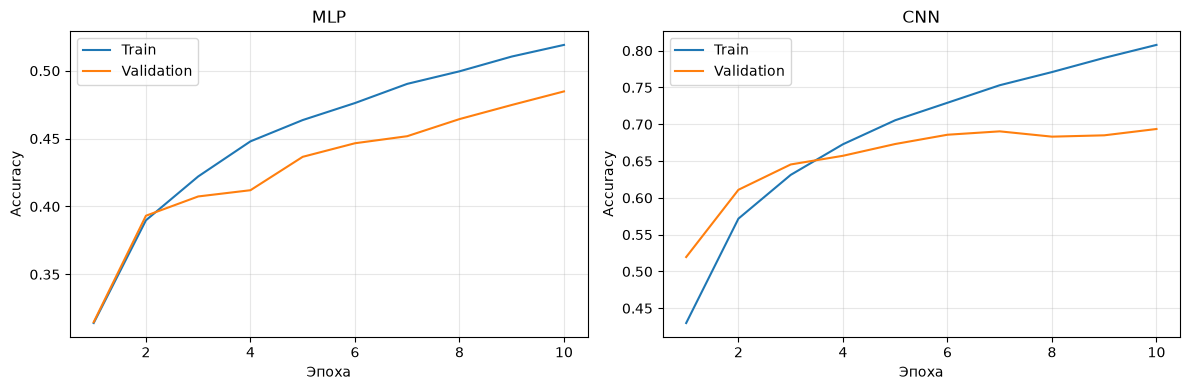

In [5]:
results = [
    ("KNN", len(x_classical), knn_accuracy),
    ("SVM", len(x_classical), svm_accuracy),
    ("MLP", len(x_fit), test_accuracy_mlp),
    ("CNN", len(x_fit), test_accuracy_cnn),
]
print(f"{'Модель':<8} {'Train':>8} {'Test accuracy':>15}")
for name, train_size, accuracy in results:
    print(f"{name:<8} {train_size:>8} {accuracy:>15.4f}")
print("Объёмы обучения различаются: сравнение имеет ограничение.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name, history in zip(
    axes, ("MLP", "CNN"), (history_mlp, history_cnn)
):
    epoch_numbers = np.arange(1, len(history.history["accuracy"]) + 1)
    ax.plot(epoch_numbers, history.history["accuracy"], label="Train")
    ax.plot(epoch_numbers, history.history["val_accuracy"], label="Validation")
    ax.set_title(name)
    ax.set_xlabel("Эпоха")
    ax.set_ylabel("Accuracy")
    ax.legend()
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 6. Отдельные предсказания

Выбираем семь test-изображений с фиксированным seed.
Примеры иллюстрируют ошибки и совпадения моделей, но не заменяют метрику
на всей тестовой выборке. Порядок названий соответствует классам CIFAR-10.

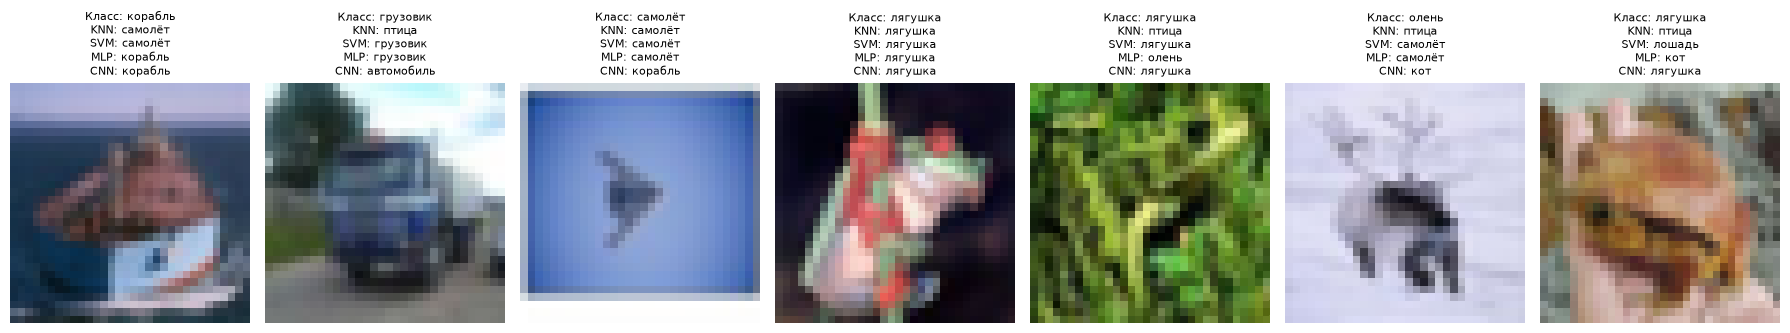

In [6]:
class_names = [
    "самолёт", "автомобиль", "птица", "кот", "олень",
    "собака", "лягушка", "лошадь", "корабль", "грузовик",
]
y_pred_mlp = model_mlp.predict(X_test, verbose=0).argmax(axis=1)
y_pred_cnn = model_cnn.predict(x_test, verbose=0).argmax(axis=1)
indices = rng.choice(len(x_test), size=7, replace=False)

fig, axes = plt.subplots(1, len(indices), figsize=(18, 4))
for ax, idx in zip(axes, indices):
    ax.imshow(x_test[idx])
    ax.set_title(
        f"Класс: {class_names[y_test[idx]]}\n"
        f"KNN: {class_names[y_pred_knn[idx]]}\n"
        f"SVM: {class_names[y_pred_svm[idx]]}\n"
        f"MLP: {class_names[y_pred_mlp[idx]]}\n"
        f"CNN: {class_names[y_pred_cnn[idx]]}",
        fontsize=8,
    )
    ax.axis("off")
fig.tight_layout()
plt.show()

## 7. Интерпретация и ограничения

Test accuracy текущего запуска: KNN **0.2727**,
SVM **0.3100**, MLP **0.4838**,
CNN **0.6997**.
MLP и CNN получали одинаковые данные и обучались по 10 эпох.
При этих параметрах CNN точнее MLP на 21.59 процентного пункта.

У CNN к концу обучения train accuracy достигает **0.8079**, а validation
accuracy — **0.6936**. Разрыв увеличивается, и validation accuracy
на последних эпохах меняется мало. Это признаки переобучения,
которые важно учитывать вместе с итоговой test accuracy.

KNN/SVM обучались на 5 000 изображениях, MLP/CNN — на 45 000.
Разные объёмы обучения ограничивают выводы о различиях архитектур.
Для сравнения при одинаковом бюджете нужен отдельный эксперимент:
обучение всех четырёх моделей на одной подвыборке с одинаковыми
разбиениями и несколькими seed.
